In [1]:
import os
import re
import html
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,ConfusionMatrixDisplay


In [2]:
DATA_PATH = os.path.join("data", "IMDB Dataset.csv")
MODEL_DIR = "models"
MODEL_PATH = os.path.join(MODEL_DIR, "sentiment_model.pkl")

os.makedirs(MODEL_DIR, exist_ok=True)

In [3]:

import os

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")
print(os.listdir())


Current folder: C:\Users\Arati\iKba\ai-projects\w12

Files in current folder:
['.ipynb_checkpoints', '.venv', 'app.py', 'confusion_matrix.png', 'IMDB Dataset.csv', 'models', 'movie.ipynb', 'requirements.txt']


In [4]:
for root, dirs, files in os.walk(os.getcwd()):
    for file in files:
        if file.lower().endswith(".csv") and "imdb" in file.lower():
            print(os.path.join(root, file))


C:\Users\Arati\iKba\ai-projects\w12\IMDB Dataset.csv
C:\Users\Arati\iKba\ai-projects\w12\.ipynb_checkpoints\IMDB Dataset-checkpoint.csv


In [5]:

import pandas as pd
from IPython.display import display

# Directly load the uploaded CSV file
df = pd.read_csv("IMDB Dataset.csv")

print("CSV uploaded and loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


CSV uploaded and loaded successfully!
Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nSentiment Percentages:")
print(
    (df["sentiment"].value_counts(normalize=True) * 100).round(2)
)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Rows: 418

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment Percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


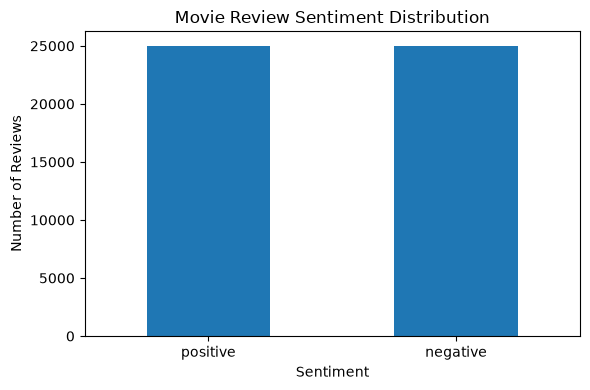

In [7]:

df["sentiment"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Movie Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:

df = df[["review", "sentiment"]].copy()

# Handle missing values
df["review"] = df["review"].fillna("").astype(str).str.strip()
df["sentiment"] = (
    df["sentiment"].fillna("").astype(str).str.strip().str.lower()
)

# Keep only non-empty reviews and valid labels
df = df[df["review"].str.len() > 0]
df = df[df["sentiment"].isin(["positive", "negative"])]

# Remove duplicate review texts
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nSentiment counts:")
print(df["sentiment"].value_counts())


Data cleaning completed!
Cleaned dataset shape: (49582, 2)

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment counts:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [9]:

X = df["review"]
y = df["sentiment"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nSample review:")
print(X.iloc[0])

print("\nSample sentiment:")
print(y.iloc[0])


Features shape: (49582,)
Target shape: (49582,)

Sample review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /

In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 39665
Testing samples: 9917


In [11]:

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

print("Model pipeline created successfully!")


Model pipeline created successfully!


In [12]:

print("Training started...")

model.fit(X_train, y_train)

print("Model training completed successfully!")


Training started...
Model training completed successfully!


In [13]:

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy Percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["negative", "positive"],
        zero_division=0
    )
)


Test Accuracy: 0.9061
Test Accuracy Percentage: 90.61%

Classification Report:
              precision    recall  f1-score   support

    negative       0.92      0.89      0.90      4940
    positive       0.89      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



In [14]:
from sklearn.metrics import confusion_matrix

Confusion Matrix:
[[4399  541]
 [ 390 4587]]


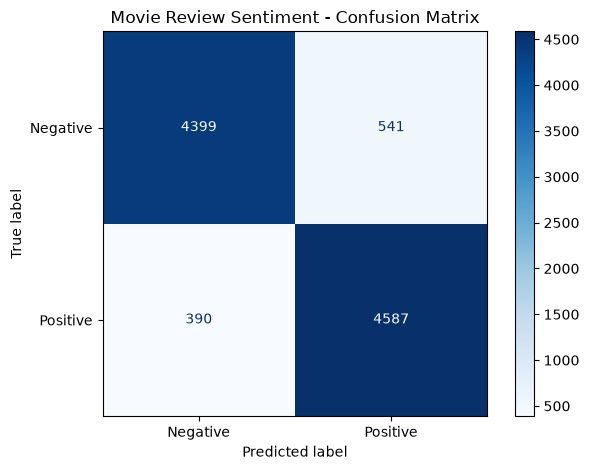

In [15]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "positive"]
)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Movie Review Sentiment - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()


In [16]:

from IPython.display import display as show_table
import pandas as pd

results = pd.DataFrame({
    "Actual Sentiment": y_test.reset_index(drop=True).to_numpy(),
    "Predicted Sentiment": y_pred
})

show_table(results.head(15))


,Actual Sentiment,Predicted Sentiment
0,negative,negative
1,positive,positive
2,positive,positive
3,negative,negative
4,negative,negative
5,positive,positive
6,negative,negative
7,negative,negative
8,positive,positive
9,negative,negative


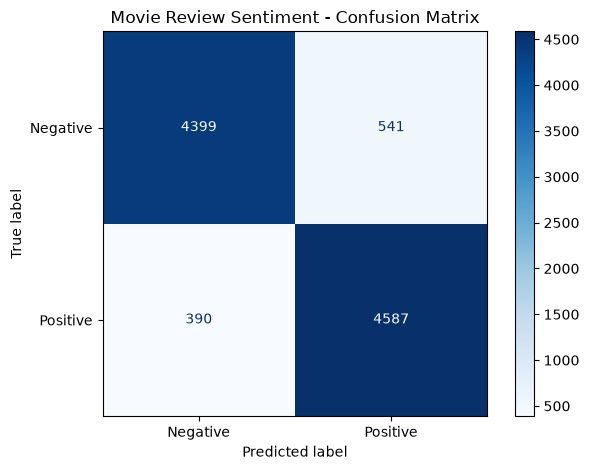

In [17]:

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Movie Review Sentiment - Confusion Matrix")
plt.tight_layout()
plt.show()


In [18]:
from IPython.display import display as show_table

results = pd.DataFrame({
    "Actual Sentiment": y_test.reset_index(drop=True).to_numpy(),
    "Predicted Sentiment": y_pred
})

show_table(results.head(15))


,Actual Sentiment,Predicted Sentiment
0,negative,negative
1,positive,positive
2,positive,positive
3,negative,negative
4,negative,negative
5,positive,positive
6,negative,negative
7,negative,negative
8,positive,positive
9,negative,negative


In [19]:

sample_reviews = [
    "This movie was absolutely fantastic and the acting was brilliant.",
    "The story was boring and the acting was terrible.",
    "I really enjoyed this film. It was entertaining and wonderful.",
    "I did not like this movie. It was a complete disappointment."
]

sample_predictions = model.predict(sample_reviews)
sample_probabilities = model.predict_proba(sample_reviews)

for review, prediction, probabilities in zip(
    sample_reviews,
    sample_predictions,
    sample_probabilities
):
    classes = list(model.classes_)
    confidence = probabilities[classes.index(prediction)] * 100

    print("\nReview:", review)
    print("Predicted Sentiment:", prediction.upper())
    print(f"Model confidence: {confidence:.2f}%")



Review: This movie was absolutely fantastic and the acting was brilliant.
Predicted Sentiment: POSITIVE
Model confidence: 80.29%

Review: The story was boring and the acting was terrible.
Predicted Sentiment: NEGATIVE
Model confidence: 99.06%

Review: I really enjoyed this film. It was entertaining and wonderful.
Predicted Sentiment: POSITIVE
Model confidence: 99.06%

Review: I did not like this movie. It was a complete disappointment.
Predicted Sentiment: NEGATIVE
Model confidence: 89.12%


In [20]:

os.makedirs("models", exist_ok=True)

MODEL_PATH = os.path.join("models", "sentiment_model.pkl")

with open(MODEL_PATH, "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")
print("Model path:", os.path.abspath(MODEL_PATH))


Model saved successfully!
Model path: C:\Users\Arati\iKba\ai-projects\w12\models\sentiment_model.pkl


In [21]:

with open(MODEL_PATH, "rb") as file:
    loaded_model = pickle.load(file)

test_review = [
    "The movie was amazing and I loved every moment."
]

prediction = loaded_model.predict(test_review)[0]

print("Review:", test_review[0])
print("Prediction:", prediction.upper())


Review: The movie was amazing and I loved every moment.
Prediction: POSITIVE
